In [50]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [59]:
z_i = torch.load("../z_i.pt").detach().cpu()
z_j = torch.load("../z_j.pt").detach().cpu()

In [60]:
logits = torch.mm(z_i, z_j.t()) / 0.2

# Create labels for positive pairs
labels = torch.arange(logits.size(0), device=logits.device)

# Compute the loss
loss = torch.nn.functional.cross_entropy(logits, labels)

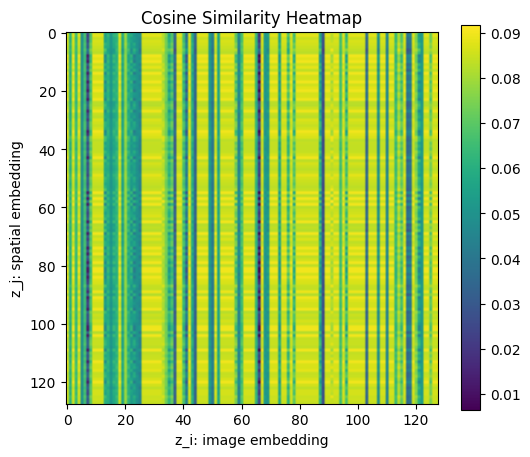

In [61]:
# Normalize (important for cosine sim)
z_i_norm = F.normalize(z_i, dim=-1)
z_j_norm = F.normalize(z_j, dim=-1)

# Cosine similarity matrix: (B, B)
sim_matrix = torch.matmul(z_i_norm, z_j_norm.T).cpu().numpy()

# Plot heatmap
plt.figure(figsize=(6, 5))
plt.imshow(sim_matrix, cmap='viridis')
plt.colorbar()
plt.title("Cosine Similarity Heatmap")
plt.xlabel("z_i: image embedding")
plt.ylabel("z_j: spatial embedding")
plt.show()

In [54]:
print("z_i mean/std:", z_i.mean().item(), z_i.std().item())
print("z_j mean/std:", z_j.mean().item(), z_j.std().item())

z_i mean/std: -0.0030858521349728107 0.08833716064691544
z_j mean/std: 0.000655672512948513 0.08838861435651779


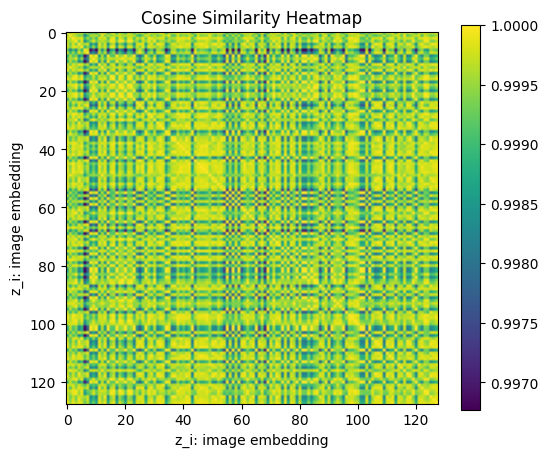

In [55]:
# Normalize (important for cosine sim)
z_i_norm = F.normalize(z_i, dim=-1)
z_j_norm = F.normalize(z_i, dim=-1)

# Cosine similarity matrix: (B, B)
sim_matrix = torch.matmul(z_i_norm, z_j_norm.T).cpu().numpy()

# Plot heatmap
plt.figure(figsize=(6, 5))
plt.imshow(sim_matrix, cmap='viridis')
plt.colorbar()
plt.title("Cosine Similarity Heatmap")
plt.xlabel("z_i: image embedding")
plt.ylabel("z_i: image embedding")
plt.show()